# Step-by-Step Machine Learning Workflow

## Dataset: YojanaMitra — Government Scheme Eligibility

**Project:** YojanaMitra, an NLP-based multilingual government-scheme eligibility assistant
**Task:** Binary classification — given a citizen's profile and a scheme, predict whether
that citizen is **eligible** for that scheme

---

### The question this notebook actually asks

YojanaMitra decides eligibility with a **deterministic rule engine**: each scheme carries
machine-readable clauses (`annual_income_inr <= 700000`, `occupation in [farmer]`, …) and a
citizen passes or fails each clause. The benchmark labels in `data/gold_set.json` are the
output of running that engine over hand-written ground-truth profiles.

So the experiment here is precise, and worth stating before any modelling:

> **Can standard baseline ML models recover the eligibility rules from labelled examples
> alone — without ever being shown the rules?**

That is a real, answerable question, and the answer decides something the project cares
about: whether the hand-written rule engine could be replaced by a learned model. It is
*not* a claim that the scheme criteria in the corpus are legally correct — the corpus is a
development seed, and its own provenance note says so.

This notebook follows the eleven-step workflow from the lab handout, one numbered section
per step.

In [1]:
# Imports and global settings
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
import json
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA = Path("data")
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 160
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 50)

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.4 | pandas 3.0.2


---
## 1. Dataset Understanding

Two source files, both from the YojanaMitra project itself:

* `data/schemes.json` — the scheme corpus: each scheme's metadata and its
  machine-readable eligibility clauses
* `data/gold_set.json` — the evaluation benchmark: citizen personas written in free text,
  each with a ground-truth structured profile and the set of schemes they qualify for

In [2]:
gold_raw = json.loads((DATA / "gold_set.json").read_text(encoding="utf-8"))
schemes_raw = json.loads((DATA / "schemes.json").read_text(encoding="utf-8"))

gold = gold_raw["data"]
schemes = schemes_raw["schemes"]

print("Dataset name   : YojanaMitra scheme-eligibility benchmark")
print("Source         : the YojanaMitra project's own data/ directory")
print("                 schemes.json  -> the scheme corpus (eligibility clauses)")
print("                 gold_set.json -> the labelled persona benchmark")
print("Provenance     :", schemes_raw["provenance"]["kind"])
print()
print("Benchmark items (persona utterances):", len(gold))
print("Distinct personas                   :", len(set(g["persona"] for g in gold)))
print("Phrasings per persona               :",
      dict(collections.Counter(g["phrasing"] for g in gold)))
print("Schemes in the corpus               :", len(schemes))

Dataset name   : YojanaMitra scheme-eligibility benchmark
Source         : the YojanaMitra project's own data/ directory
                 schemes.json  -> the scheme corpus (eligibility clauses)
                 gold_set.json -> the labelled persona benchmark
Provenance     : development-seed

Benchmark items (persona utterances): 60
Distinct personas                   : 20
Phrasings per persona               : {'plain': 20, 'telegraphic': 20, 'code_mixed': 20}
Schemes in the corpus               : 40


In [3]:
# How the labels were produced — read it straight from the file, do not paraphrase
print("METHODOLOGY NOTE recorded in gold_set.json:")
print()
import textwrap
print(textwrap.fill(gold_raw["methodology"], 88))

METHODOLOGY NOTE recorded in gold_set.json:

Labels are derived by running the deterministic rule filter over a hand-written ground-
truth profile for each persona. The benchmark measures recovery of that conclusion from
free text (extraction + retrieval). It does NOT validate that the corpus states Indian
eligibility law correctly; that requires human verification against the live portal.


In [4]:
# Framing the supervised learning problem
n_personas = len(set(g["persona"] for g in gold))
print("UNIT OF ANALYSIS")
print("  One row = one (citizen persona, scheme) pair.")
print(f"  {n_personas} distinct personas x {len(schemes)} schemes = "
      f"{n_personas * len(schemes)} rows")
print()
print("TARGET VARIABLE")
print("  eligible : 1 if the scheme is in that persona's expected_schemes, else 0")
print()
print("PROBLEM TYPE")
print("  Supervised CLASSIFICATION - the target is a discrete label")
print()
print("NUMBER OF CLASSES")
print("  2 (binary): eligible / not eligible")
print()
print("INPUT FEATURES")
print("  Built in step 2 from two sides of each pair:")
print("    citizen side - age, income, land, residence, category, occupation,")
print("                   special categories, education stage, dependents")
print("    scheme  side - which scheme, central or state, number of clauses,")
print("                   scheme category, and whether the scheme's state matches")

UNIT OF ANALYSIS
  One row = one (citizen persona, scheme) pair.
  20 distinct personas x 40 schemes = 800 rows

TARGET VARIABLE
  eligible : 1 if the scheme is in that persona's expected_schemes, else 0

PROBLEM TYPE
  Supervised CLASSIFICATION - the target is a discrete label

NUMBER OF CLASSES
  2 (binary): eligible / not eligible

INPUT FEATURES
  Built in step 2 from two sides of each pair:
    citizen side - age, income, land, residence, category, occupation,
                   special categories, education stage, dependents
    scheme  side - which scheme, central or state, number of clauses,
                   scheme category, and whether the scheme's state matches


In [5]:
# The strict vs tolerant label sets
n_exp = [len(g["expected_schemes"]) for g in gold]
n_acc = [len(g["acceptable_schemes"]) for g in gold]
print(f"expected_schemes   per persona: min {min(n_exp)}, max {max(n_exp)}, "
      f"mean {np.mean(n_exp):.1f}")
print(f"acceptable_schemes per persona: min {min(n_acc)}, max {max(n_acc)}, "
      f"mean {np.mean(n_acc):.1f}")
print()
print("The benchmark ships two label sets. 'expected' is the strict rule-engine answer;")
print("'acceptable' is a wider tolerance band used to avoid punishing near-misses.")
print("We label with the STRICT set, because a fuzzy target would make every metric")
print("in step 9 impossible to interpret.")

expected_schemes   per persona: min 2, max 11, mean 7.7
acceptable_schemes per persona: min 6, max 28, mean 19.1

The benchmark ships two label sets. 'expected' is the strict rule-engine answer;
'acceptable' is a wider tolerance band used to avoid punishing near-misses.
We label with the STRICT set, because a fuzzy target would make every metric
in step 9 impossible to interpret.


---
## 2. Load the Dataset

The two JSON files are not a table, so this step is a genuine transformation: the nested
persona profiles and scheme records are flattened into one tidy dataframe where each row is
a (persona, scheme) pair and each column is a feature.

Three groups of features are built:

| Group | Examples | Why |
|---|---|---|
| **Citizen** | age, income, land, occupation, category, special categories | what the rules test |
| **Scheme** | which scheme, central/state, clause count, scheme category | which rules apply |
| **Interaction** | `state_match` | a state scheme only applies in its own state |

In [6]:
# 2.1 Build the vocabularies we will one-hot encode, from the data itself
occ_vocab = sorted({o for g in gold for o in g["profile"].get("occupation", [])})
spec_vocab = sorted({s for g in gold
                     for s in g["profile"].get("special_categories", [])})
edu_vocab = sorted({g["profile"]["education_stage"] for g in gold
                    if g["profile"].get("education_stage")})
cat_vocab = sorted({g["profile"]["category"] for g in gold
                    if g["profile"].get("category")})
scheme_cat_vocab = sorted({c for s in schemes for c in s["category"]})

print("occupation values      :", occ_vocab)
print("special_categories     :", spec_vocab)
print("education_stage values :", edu_vocab)
print("social category values :", cat_vocab)
print("scheme categories      :", len(scheme_cat_vocab), "distinct")

occupation values      : ['farmer', 'fisherman', 'labourer', 'salaried', 'self_employed', 'shopkeeper', 'student', 'unemployed', 'weaver']
special_categories     : ['bpl', 'differently_abled', 'landless', 'widow']
education_stage values : ['class_9_10', 'postgraduate', 'undergraduate']
social category values : ['obc', 'sc', 'st']
scheme categories      : 33 distinct


In [7]:
# 2.2 Flatten one (persona, scheme) pair into a feature dictionary
def build_row(item, scheme):
    p = item["profile"]
    deps = p.get("dependents", []) or []
    row = {
        # --- identifiers (not features; used for grouping and inspection) ---
        "persona":   item["persona"],
        "phrasing":  item["phrasing"],
        "scheme_id": scheme["id"],

        # --- citizen side: numeric ---
        "age":               p.get("age", np.nan),
        "annual_income_inr": p.get("annual_income_inr", np.nan),
        "land_acres":        p.get("land_acres", np.nan),
        "n_dependents":      len(deps),

        # --- citizen side: binary ---
        "residence_rural":  1 if p.get("residence") == "rural" else 0,
        "gender_female":    1 if p.get("gender") == "female" else 0,
        "gender_known":     1 if p.get("gender") else 0,
        "dep_has_female":   int(any(d.get("gender") == "female" for d in deps)),
        "dep_has_student":  int(any(d.get("education_stage") for d in deps)),

        # --- scheme side ---
        "scheme_is_state":  1 if scheme["level"] == "state" else 0,
        "scheme_n_clauses": len(scheme["clauses"]),
        "scheme_n_constrained_clauses":
            sum(1 for c in scheme["clauses"] if c["constraint"]),

        # --- interaction: does this scheme apply in the citizen's state? ---
        "state_match": 1 if (scheme["state"] is None
                             or scheme["state"] == p.get("state")) else 0,
    }
    # multi-hot blocks
    for o in occ_vocab:
        row[f"occ_{o}"] = int(o in (p.get("occupation") or []))
    for s in spec_vocab:
        row[f"spec_{s}"] = int(s in (p.get("special_categories") or []))
    for e in edu_vocab:
        row[f"edu_{e}"] = int(p.get("education_stage") == e)
    for c in cat_vocab:
        row[f"socialcat_{c}"] = int(p.get("category") == c)
    for c in scheme_cat_vocab:
        row[f"schemecat_{c}"] = int(c in scheme["category"])

    # --- target ---
    row["eligible"] = int(scheme["id"] in item["expected_schemes"])
    return row


rows = [build_row(item, scheme) for item in gold for scheme in schemes]
df = pd.DataFrame(rows)

print("Raw pair table shape:", df.shape)
print(f"  {len(gold)} persona utterances x {len(schemes)} schemes = {len(df)} rows")
df.head()

Raw pair table shape: (2400, 69)
  60 persona utterances x 40 schemes = 2400 rows


,persona,phrasing,scheme_id,age,annual_income_inr,land_acres,n_dependents,residence_rural,gender_female,gender_known,dep_has_female,dep_has_student,scheme_is_state,scheme_n_clauses,scheme_n_constrained_clauses,state_match,occ_farmer,occ_fisherman,occ_labourer,occ_salaried,occ_self_employed,occ_shopkeeper,occ_student,occ_unemployed,occ_weaver,...,schemecat_fisheries,schemecat_girl child,schemecat_health,schemecat_household,schemecat_housing,schemecat_income support,schemecat_insurance,schemecat_livelihood,schemecat_marriage assistance,schemecat_maternity,schemecat_one-time assistance,schemecat_pension,schemecat_rural,schemecat_savings,schemecat_scholarship,schemecat_senior citizen,schemecat_skill,schemecat_social security,schemecat_social welfare,schemecat_subsidy,schemecat_urban,schemecat_wages,schemecat_women,schemecat_youth,eligible
0,ap-small-farmer-daughter,plain,pm-kisan,44,180000,2.0,1,1,0,0,1,1,0,4,3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,ap-small-farmer-daughter,plain,pmfby,44,180000,2.0,1,1,0,0,1,1,0,3,1,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,ap-small-farmer-daughter,plain,kcc,44,180000,2.0,1,1,0,0,1,1,0,3,2,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
3,ap-small-farmer-daughter,plain,pmkmy,44,180000,2.0,1,1,0,0,1,1,0,3,3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
4,ap-small-farmer-daughter,plain,pmvishwakarma,44,180000,2.0,1,1,0,0,1,1,0,3,2,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0


---
## 3. Explore the Dataset (EDA)

Four questions:

1. Is anything missing, and is the missingness random or structural?
2. Are there duplicate records?
3. How is the target distributed?
4. Which features actually separate eligible from ineligible?

In [8]:
# 3.1 Structure
print("Rows:", len(df), " Columns:", df.shape[1])
print()
print("Column groups:")
groups = {
    "identifier":  ["persona", "phrasing", "scheme_id"],
    "citizen numeric": ["age", "annual_income_inr", "land_acres", "n_dependents"],
    "citizen binary":  [c for c in df.columns
                        if c.startswith(("occ_", "spec_", "edu_", "socialcat_",
                                         "gender_", "dep_", "residence_"))],
    "scheme":      [c for c in df.columns if c.startswith("scheme")],
    "interaction": ["state_match"],
    "target":      ["eligible"],
}
for g, cols in groups.items():
    print(f"  {g:<17} {len(cols):>3} columns")

Rows: 2400  Columns: 69

Column groups:
  identifier          3 columns
  citizen numeric     4 columns
  citizen binary     24 columns
  scheme             37 columns
  interaction         1 columns
  target              1 columns


In [9]:
# 3.2 Missing values — and WHY they are missing
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
for col, n in missing.items():
    print(f"  {col:<20} {n:>4} / {len(df)}  ({n/len(df):.1%})")
print()
print("This missingness is STRUCTURAL, not random. 'land_acres' is absent whenever the")
print("persona is not a landholder at all - a student, a street vendor, a weaver. The")
print("absence is itself informative, which changes how it should be imputed (step 5).")

Columns with missing values:
  land_acres           1560 / 2400  (65.0%)

This missingness is STRUCTURAL, not random. 'land_acres' is absent whenever the
persona is not a landholder at all - a student, a street vendor, a weaver. The
absence is itself informative, which changes how it should be imputed (step 5).


In [10]:
# 3.3 Duplicates — the finding that shapes the rest of the notebook
print("Fully duplicated rows (all columns):", int(df.duplicated().sum()))

feature_cols_probe = [c for c in df.columns
                      if c not in ("persona", "phrasing", "scheme_id", "eligible")]
dupe_features = int(df.duplicated(subset=feature_cols_probe + ["scheme_id"]).sum())
print("Rows with a duplicate FEATURE vector:", dupe_features, f"/ {len(df)}")
print()
print("Why: the benchmark writes each persona three times - 'plain', 'telegraphic' and")
print("'code_mixed' phrasings of the SAME underlying profile. Those three utterances are")
print("different NLP inputs, but once we use the structured profile they collapse to one")
print("identical row. 60 utterances x 40 schemes = 2400 rows, but only 800 are distinct.")
print()
print("Left untreated this is a data-leakage trap: the same profile would land in both")
print("the training and the test set. Step 5 removes it.")

Fully duplicated rows (all columns): 0
Rows with a duplicate FEATURE vector: 1600 / 2400

Why: the benchmark writes each persona three times - 'plain', 'telegraphic' and
'code_mixed' phrasings of the SAME underlying profile. Those three utterances are
different NLP inputs, but once we use the structured profile they collapse to one
identical row. 60 utterances x 40 schemes = 2400 rows, but only 800 are distinct.

Left untreated this is a data-leakage trap: the same profile would land in both
the training and the test set. Step 5 removes it.


In [11]:
# 3.4 Target distribution
counts = df["eligible"].value_counts().sort_index()
print("Target distribution (before de-duplication)")
for k, v in counts.items():
    label = "eligible" if k else "not eligible"
    print(f"  {k} = {label:<13} {v:>5} pairs  ({v/len(df):6.2%})")
print()
print("IMBALANCED: roughly 1 in 5. Most citizens qualify for a minority of the 40 schemes.")
print("A model that always predicts 'not eligible' would score about 80% accuracy while")
print("recommending nothing to anybody. Accuracy is therefore a MISLEADING metric here and")
print("precision / recall / F1 on the eligible class are the ones that matter.")

Target distribution (before de-duplication)
  0 = not eligible   1941 pairs  (80.88%)
  1 = eligible        459 pairs  (19.12%)

IMBALANCED: roughly 1 in 5. Most citizens qualify for a minority of the 40 schemes.
A model that always predicts 'not eligible' would score about 80% accuracy while
recommending nothing to anybody. Accuracy is therefore a MISLEADING metric here and
precision / recall / F1 on the eligible class are the ones that matter.


In [12]:
# 3.5 Which features separate the classes?
numeric_probe = ["age", "annual_income_inr", "land_acres", "n_dependents",
                 "state_match", "scheme_is_state", "residence_rural",
                 "gender_female", "scheme_n_clauses"]
corr = df[numeric_probe + ["eligible"]].corr()["eligible"].drop("eligible")
print("Correlation with 'eligible':")
print(corr.sort_values(key=abs, ascending=False).round(3).to_string())
print()
print("Note how weak these are. Eligibility is a CONJUNCTION of clauses - income AND")
print("occupation AND state AND age - so no single feature is linearly predictive.")
print("That is a strong hint that linear models will struggle and tree models will not.")

Correlation with 'eligible':
state_match          0.232
scheme_is_state     -0.180
scheme_n_clauses    -0.137
gender_female        0.050
n_dependents         0.036
annual_income_inr   -0.033
land_acres           0.026
residence_rural      0.020
age                  0.014

Note how weak these are. Eligibility is a CONJUNCTION of clauses - income AND
occupation AND state AND age - so no single feature is linearly predictive.
That is a strong hint that linear models will struggle and tree models will not.


In [13]:
# 3.6 Eligibility rate varies enormously by scheme
per_scheme = (df.groupby("scheme_id")["eligible"].mean()
                .sort_values(ascending=False))
print("Most widely available schemes (share of personas eligible):")
print((per_scheme.head(6) * 100).round(1).astype(str).add(" %").to_string())
print()
print("Most restrictive schemes:")
print((per_scheme.tail(6) * 100).round(1).astype(str).add(" %").to_string())

Most widely available schemes (share of personas eligible):
scheme_id
pmsby           95.0 %
pmegp           95.0 %
pmjjby          85.0 %
atal-pension    70.0 %
mgnrega         65.0 %
pmmvy           40.0 %

Most restrictive schemes:
scheme_id
up-kanya-sumangala            5.0 %
ts-kalyana-lakshmi            5.0 %
ap-jagananna-vidya-deevena    0.0 %
pm-yasasvi                    0.0 %
saksham-scholarship           0.0 %
sukanya-samriddhi             0.0 %


---
## 4. Visualise the Data

Four plots, matching the four named in the handout — a bar chart, a histogram, a box plot
and a correlation heatmap.

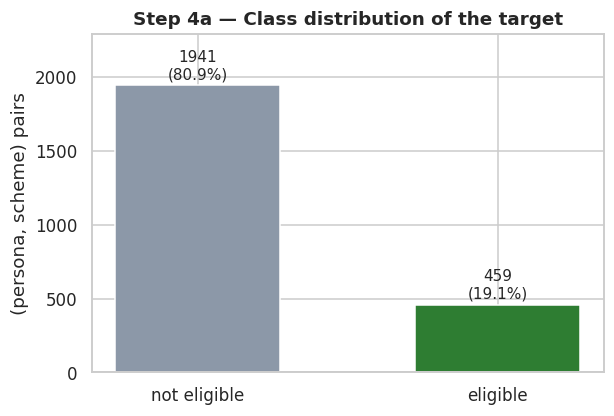

In [14]:
# 4.1 BAR CHART — class distribution of the target
fig, ax = plt.subplots(figsize=(6, 4))
labels = ["not eligible", "eligible"]
vals = [int((df["eligible"] == 0).sum()), int((df["eligible"] == 1).sum())]
bars = ax.bar(labels, vals, color=["#8c98a8", "#2e7d32"], width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 25, f"{v}\n({v/sum(vals):.1%})",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Step 4a — Class distribution of the target",
             fontsize=12, weight="bold")
ax.set_ylabel("(persona, scheme) pairs")
ax.set_ylim(0, max(vals) * 1.18)
plt.savefig(FIGDIR / "01_class_distribution.png"); plt.show()

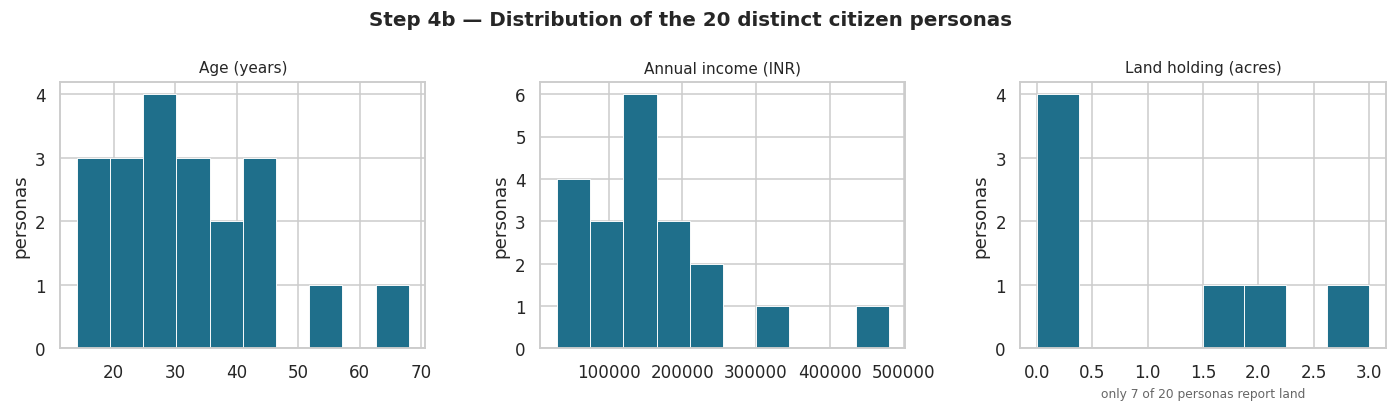

In [15]:
# 4.2 HISTOGRAM — citizen attributes, eligible vs not
citizen_level = df.drop_duplicates("persona")[
    ["persona", "age", "annual_income_inr", "land_acres", "n_dependents"]]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
specs = [("age", "Age (years)", 10),
         ("annual_income_inr", "Annual income (INR)", 10),
         ("land_acres", "Land holding (acres)", 8)]
for ax, (col, xlabel, bins) in zip(axes, specs):
    ax.hist(citizen_level[col].dropna(), bins=bins,
            color="#1f6f8b", edgecolor="white", linewidth=0.6)
    ax.set_title(f"{xlabel}", fontsize=10)
    ax.set_ylabel("personas")
n_land = int(citizen_level["land_acres"].notna().sum())
axes[2].set_xlabel(f"only {n_land} of 20 personas report land", fontsize=8, color="#666")
fig.suptitle("Step 4b — Distribution of the 20 distinct citizen personas",
             fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig(FIGDIR / "02_histograms.png"); plt.show()

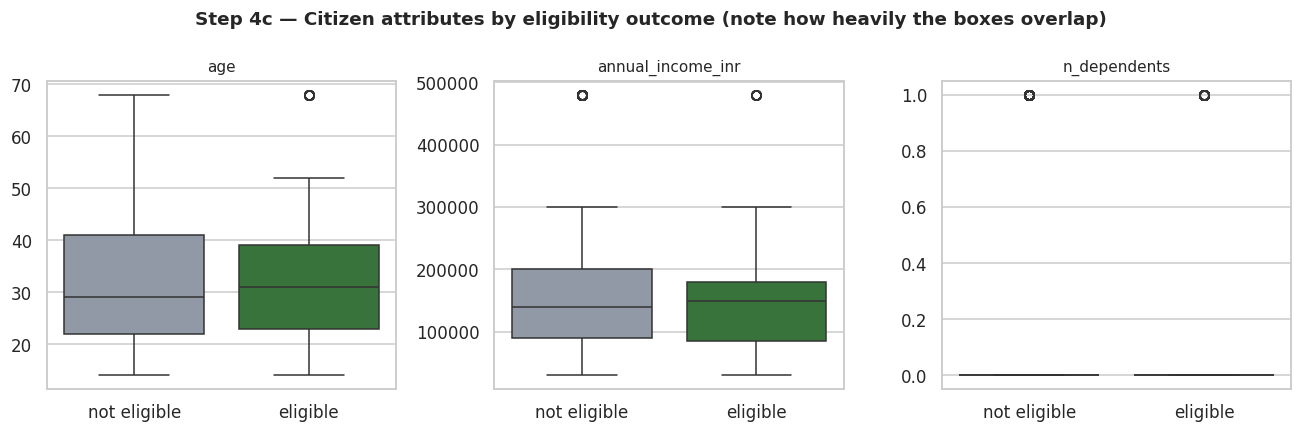

In [16]:
# 4.3 BOX PLOT — do eligible pairs differ in citizen attributes?
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["age", "annual_income_inr", "n_dependents"]):
    plot_df = df[[col, "eligible"]].copy()
    plot_df["class"] = plot_df["eligible"].map({0: "not eligible", 1: "eligible"})
    sns.boxplot(data=plot_df, x="class", y=col, ax=ax,
                order=["not eligible", "eligible"], hue="class", legend=False,
                palette={"not eligible": "#8c98a8", "eligible": "#2e7d32"})
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Step 4c — Citizen attributes by eligibility outcome "
             "(note how heavily the boxes overlap)", fontsize=12, weight="bold")
plt.tight_layout()
plt.savefig(FIGDIR / "03_boxplots.png"); plt.show()

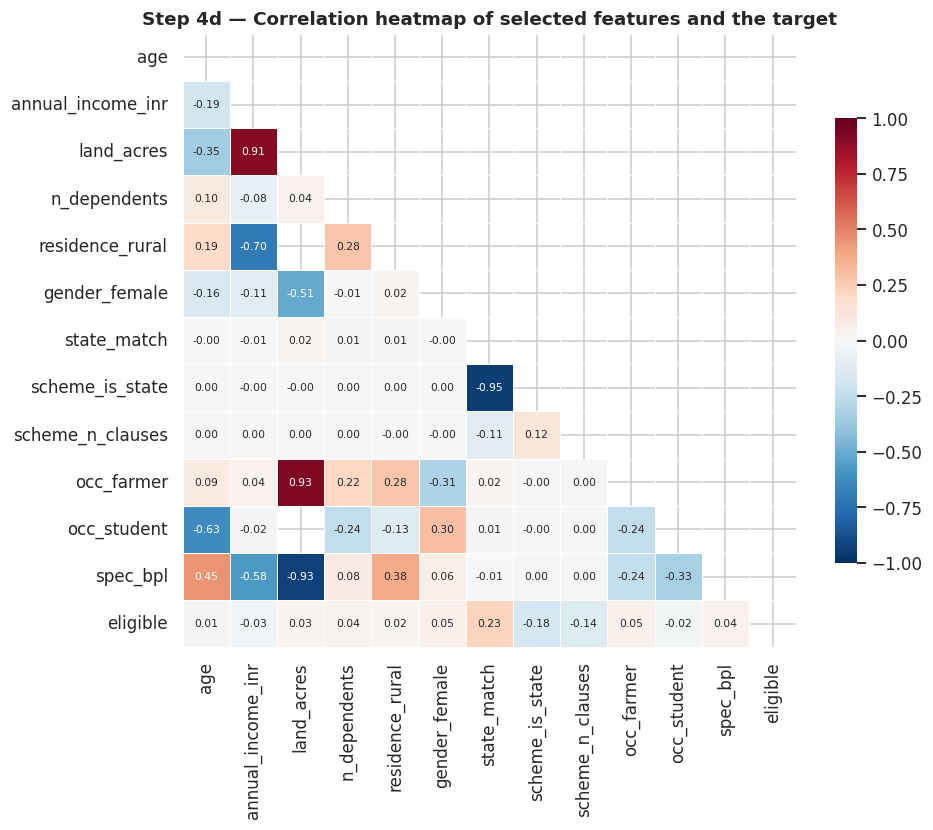

The 'eligible' row is almost entirely pale — no single feature correlates
strongly with the target. This is the signature of a rule-based, conjunctive
target, and it is the single most important thing this heatmap tells us.


In [17]:
# 4.4 CORRELATION HEATMAP
heat_cols = ["age", "annual_income_inr", "land_acres", "n_dependents",
             "residence_rural", "gender_female", "state_match",
             "scheme_is_state", "scheme_n_clauses",
             "occ_farmer", "occ_student", "spec_bpl", "eligible"]
heat_cols = [c for c in heat_cols if c in df.columns]
corr_m = df[heat_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr_m, dtype=bool))
sns.heatmap(corr_m, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Step 4d — Correlation heatmap of selected features and the target",
             fontsize=12, weight="bold")
plt.savefig(FIGDIR / "04_correlation_heatmap.png"); plt.show()

print("The 'eligible' row is almost entirely pale — no single feature correlates")
print("strongly with the target. This is the signature of a rule-based, conjunctive")
print("target, and it is the single most important thing this heatmap tells us.")

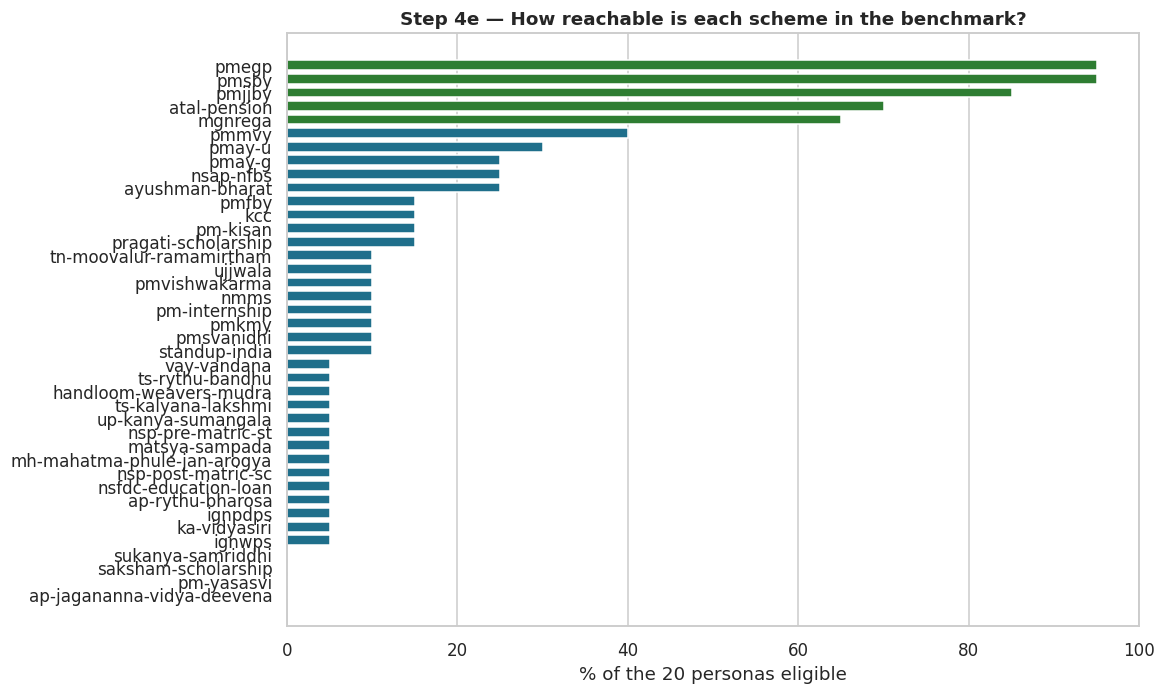

4 of 40 schemes are matched by NO persona in the benchmark:
  ap-jagananna-vidya-deevena, pm-yasasvi, saksham-scholarship, sukanya-samriddhi

These contribute only negative examples. They are not a bug - they show the
benchmark's 20 personas do not exercise the whole corpus, which is a real
coverage limitation worth reporting.


In [18]:
# 4.5 EXTRA — eligibility rate per scheme, the most project-relevant view
fig, ax = plt.subplots(figsize=(10, 7))
ps = df.groupby("scheme_id")["eligible"].mean().sort_values()
colours = ["#c0504d" if v == 0 else "#2e7d32" if v > 0.5 else "#1f6f8b"
           for v in ps.values]
ax.barh(ps.index, ps.values * 100, color=colours, height=0.72)
ax.set_xlabel("% of the 20 personas eligible")
ax.set_title("Step 4e — How reachable is each scheme in the benchmark?",
             fontsize=12, weight="bold")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
plt.savefig(FIGDIR / "05_scheme_eligibility.png"); plt.show()

never = ps[ps == 0]
print(f"{len(never)} of {len(ps)} schemes are matched by NO persona in the benchmark:")
print(" ", ", ".join(never.index))
print()
print("These contribute only negative examples. They are not a bug - they show the")
print("benchmark's 20 personas do not exercise the whole corpus, which is a real")
print("coverage limitation worth reporting.")

---
## 5. Clean and Preprocess the Data

Three substantive operations here, each of which changes the result — this is not a
formality on this dataset.

In [19]:
# 5.1 DE-DUPLICATION — collapse the three phrasings of each persona
before = len(df)
df_clean = df[df["phrasing"] == "plain"].copy().reset_index(drop=True)

print(f"[clean] Rows: {before} -> {len(df_clean)}")
print(f"        Kept one utterance per persona ({df_clean['persona'].nunique()} personas")
print(f"        x {df_clean['scheme_id'].nunique()} schemes).")
print()
print("        The 'telegraphic' and 'code_mixed' phrasings describe the SAME profile,")
print("        so once we model from structured features they add zero information and")
print("        would triple-count every persona. They matter for the NLP extraction")
print("        stage of YojanaMitra, not for this classification experiment.")

[clean] Rows: 2400 -> 800
        Kept one utterance per persona (20 personas
        x 40 schemes).

        The 'telegraphic' and 'code_mixed' phrasings describe the SAME profile,
        so once we model from structured features they add zero information and
        would triple-count every persona. They matter for the NLP extraction
        stage of YojanaMitra, not for this classification experiment.


In [20]:
# 5.2 MISSING VALUES — imputed with an explicit indicator, not a silent fill
num_cols = ["age", "annual_income_inr", "land_acres", "n_dependents"]
for c in num_cols:
    n_missing = int(df_clean[c].isna().sum())
    if n_missing:
        df_clean[f"{c}_missing"] = df_clean[c].isna().astype(int)
        fill = 0.0 if c == "land_acres" else df_clean[c].median()
        df_clean[c] = df_clean[c].fillna(fill)
        print(f"[clean] {c}: {n_missing} missing -> filled with {fill}, "
              f"flag column '{c}_missing' added")
    else:
        print(f"[clean] {c}: no missing values")

print()
print("        'land_acres' is filled with 0, not the median: a missing land field means")
print("        the persona is not a landholder, so 0 acres is the truthful value. The")
print("        companion '_missing' flag lets a model distinguish 'genuinely landless'")
print("        from 'not stated' rather than conflating them.")

[clean] age: no missing values
[clean] annual_income_inr: no missing values
[clean] land_acres: 520 missing -> filled with 0.0, flag column 'land_acres_missing' added
[clean] n_dependents: no missing values

        'land_acres' is filled with 0, not the median: a missing land field means
        the persona is not a landholder, so 0 acres is the truthful value. The
        companion '_missing' flag lets a model distinguish 'genuinely landless'
        from 'not stated' rather than conflating them.


In [21]:
# 5.3 CONSTANT FEATURES — drop columns that carry no signal after de-duplication
feature_cols = [c for c in df_clean.columns
                if c not in ("persona", "phrasing", "scheme_id", "eligible")]
variances = df_clean[feature_cols].var()
constant = variances[variances == 0].index.tolist()

print(f"[clean] Zero-variance features: {len(constant)}")
if constant:
    for c in constant:
        print(f"          dropped '{c}'")
    df_clean = df_clean.drop(columns=constant)
    feature_cols = [c for c in feature_cols if c not in constant]
print(f"        Feature count: {len(feature_cols)}")

[clean] Zero-variance features: 0
        Feature count: 66


In [22]:
# 5.4 ENCODING — scheme identity is the one remaining categorical
print("[clean] scheme_id has", df_clean["scheme_id"].nunique(),
      "levels -> one-hot encoded")
scheme_dummies = pd.get_dummies(df_clean["scheme_id"], prefix="sch").astype(int)
df_model = pd.concat([df_clean[feature_cols + ["eligible"]], scheme_dummies], axis=1)
feature_cols = [c for c in df_model.columns if c != "eligible"]

print("        All other features are already numeric or binary — no further encoding.")
print()
print("Final modelling table:", df_model.shape,
      f"-> {len(feature_cols)} features + 1 target")

[clean] scheme_id has 40 levels -> one-hot encoded
        All other features are already numeric or binary — no further encoding.

Final modelling table: (800, 107) -> 106 features + 1 target


In [23]:
# 5.5 Class balance after cleaning
counts = df_model["eligible"].value_counts().sort_index()
print("Target distribution after cleaning")
for k, v in counts.items():
    label = "eligible" if k else "not eligible"
    print(f"  {k} = {label:<13} {v:>4} pairs  ({v/len(df_model):6.2%})")
print()
print("MAJORITY-CLASS BASELINE: always predicting 'not eligible' scores",
      f"{counts[0]/len(df_model):.2%} accuracy.")
print("Every model in step 8 must beat that to be worth anything at all.")

Target distribution after cleaning
  0 = not eligible   647 pairs  (80.88%)
  1 = eligible       153 pairs  (19.12%)

MAJORITY-CLASS BASELINE: always predicting 'not eligible' scores 80.88% accuracy.
Every model in step 8 must beat that to be worth anything at all.


---
## 6. Separate Input and Output

`X` holds the engineered features, `y` the eligibility label. A third array, `groups`,
holds the persona each row came from — it is not a feature, but step 7 cannot be done
correctly without it.

In [24]:
X = df_model[feature_cols].copy()
y = df_model["eligible"].copy()
groups = df_clean["persona"].copy()          # NOT a feature — used for the split

print("X (input)  shape:", X.shape)
print("y (output) shape:", y.shape)
print("groups          :", groups.nunique(), "distinct personas")
print()
print("Leak check — none of these are in X:")
for c in ["eligible", "persona", "phrasing", "scheme_id"]:
    print(f"  {c:<12} in X? {c in X.columns}")

X (input)  shape: (800, 106)
y (output) shape: (800,)
groups          : 20 distinct personas

Leak check — none of these are in X:
  eligible     in X? False
  persona      in X? False
  phrasing     in X? False
  scheme_id    in X? False


---
## 7. Split the Dataset

**This is the step where this dataset differs from a textbook one, and it is worth showing
the mentor explicitly.**

Each persona contributes 40 rows — one per scheme. A plain random split scatters those 40
rows across the train and test sets, so the model sees *the same citizen* in training and
is then asked about that citizen again at test time. It only has to remember, not
generalise, and the reported score becomes meaningless.

The correct split is **grouped by persona**: a persona is entirely in train or entirely in
test, never both. Below we run both splits and measure the difference, because that gap is
the whole argument.

In [25]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# --- the WRONG way, shown deliberately -------------------------------------
Xtr_bad, Xte_bad, ytr_bad, yte_bad = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

# --- the CORRECT way: group-aware ------------------------------------------
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

print("GROUPED SPLIT (used for all results in this notebook)")
print(f"  Train: {len(X_train):>3} rows from {g_train.nunique()} personas")
print(f"  Test : {len(X_test):>3} rows from {g_test.nunique()} personas")
print(f"  Personas appearing in BOTH sets: "
      f"{len(set(g_train) & set(g_test))}   <- must be 0")
print()
print(f"  Train eligible rate: {y_train.mean():.2%}")
print(f"  Test  eligible rate: {y_test.mean():.2%}")
print()
print("  Test personas (completely unseen during training):")
for p in sorted(set(g_test)):
    print("   -", p)

GROUPED SPLIT (used for all results in this notebook)
  Train: 560 rows from 14 personas
  Test : 240 rows from 6 personas
  Personas appearing in BOTH sets: 0   <- must be 0

  Train eligible rate: 18.75%
  Test  eligible rate: 20.00%

  Test personas (completely unseen during training):
   - ap-small-farmer-daughter
   - disabled-adult-bpl
   - sc-engineering-student
   - st-class9-student
   - urban-street-vendor
   - young-entrepreneur-sc


In [26]:
# Quantify the leakage: same model, same data, two different splits
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

probe = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)

probe.fit(Xtr_bad, ytr_bad)
bad_acc = accuracy_score(yte_bad, probe.predict(Xte_bad))
bad_f1 = f1_score(yte_bad, probe.predict(Xte_bad))

probe.fit(X_train, y_train)
good_acc = accuracy_score(y_test, probe.predict(X_test))
good_f1 = f1_score(y_test, probe.predict(X_test))

print("Random Forest, identical data, two split strategies")
print(f"  Random split  (LEAKY) : accuracy {bad_acc:.4f}   F1 {bad_f1:.4f}")
print(f"  Grouped split (HONEST): accuracy {good_acc:.4f}   F1 {good_f1:.4f}")
print(f"  Inflation from leakage: {bad_f1 - good_f1:+.4f} F1")
print()
print("The leaky number is the one that would have gone in the report if the split had")
print("been done carelessly. Everything from here uses the grouped split.")

Random Forest, identical data, two split strategies
  Random split  (LEAKY) : accuracy 0.9417   F1 0.8372
  Grouped split (HONEST): accuracy 0.8625   F1 0.5926
  Inflation from leakage: +0.2446 F1

The leaky number is the one that would have gone in the report if the split had
been done carelessly. Everything from here uses the grouped split.


---
## 8. Train Baseline ML Models

Six baselines spanning the main families, plus a trivial reference point. Each is wrapped
in a `Pipeline`, so the `StandardScaler` for the distance- and margin-based models is
fitted on the training fold only.

| Model | Family | Scaled |
|---|---|---|
| Majority-class baseline | trivial reference | — |
| Logistic Regression | linear | yes |
| K-Nearest Neighbours | distance-based | yes |
| Decision Tree | single tree | no |
| Random Forest | tree ensemble | no |
| Support Vector Machine (RBF) | margin-based | yes |
| Gaussian Naive Bayes | probabilistic | no |

In [27]:
import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


def pipe(model, scale=True):
    steps = [("scaler", StandardScaler())] if scale else []
    return Pipeline(steps + [("model", model)])


models = {
    "Majority Baseline":    pipe(DummyClassifier(strategy="most_frequent"),
                                 scale=False),
    "Logistic Regression":  pipe(LogisticRegression(max_iter=5000,
                                                    random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": pipe(KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree":        pipe(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                 scale=False),
    "Random Forest":        pipe(RandomForestClassifier(n_estimators=300,
                                                        random_state=RANDOM_STATE),
                                 scale=False),
    "SVM (RBF kernel)":     pipe(SVC(kernel="rbf", probability=True,
                                     random_state=RANDOM_STATE)),
    "Gaussian Naive Bayes": pipe(GaussianNB(), scale=False),
}

fitted, fit_times = {}, {}
for name, m in models.items():
    t0 = time.perf_counter()
    m.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - t0
    fitted[name] = m
    print(f"trained  {name:<22} in {fit_times[name]*1000:7.1f} ms")

print(f"\nAll {len(models)} models trained on {len(X_train)} rows "
      f"from {g_train.nunique()} personas.")

trained  Majority Baseline      in     0.7 ms
trained  Logistic Regression    in    10.5 ms
trained  K-Nearest Neighbours   in     4.1 ms
trained  Decision Tree          in     4.4 ms


trained  Random Forest          in   425.9 ms
trained  SVM (RBF kernel)       in    78.1 ms
trained  Gaussian Naive Bayes   in     3.5 ms

All 7 models trained on 560 rows from 14 personas.


---
## 9. Evaluate Each Model

For YojanaMitra the two errors are not symmetric:

* A **false negative** — failing to surface a scheme the citizen actually qualifies for —
  means a citizen never learns about a benefit they are entitled to. This is the failure
  the whole project exists to prevent.
* A **false positive** — recommending a scheme they do not qualify for — wastes an
  application and erodes trust, but is recoverable.

So **recall on the eligible class** is the headline number, with F1 as the balanced view.
Accuracy is reported only to show how badly it flatters a model on 20%-positive data.

Cross-validation is `StratifiedGroupKFold`, keeping personas intact in every fold.

In [28]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix)
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows_eval, preds = [], {}

for name, m in fitted.items():
    y_pred = m.predict(X_test)
    preds[name] = y_pred
    try:
        y_prob = m.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_prob)
    except Exception:
        auc = np.nan

    cv_scores = cross_val_score(m, X_train, y_train, cv=cv, groups=g_train,
                                scoring="f1")

    rows_eval.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall":    recall_score(y_test, y_pred, zero_division=0),
        "F1":        f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC":   auc,
        "CV F1 (mean)": cv_scores.mean(),
        "CV F1 (std)":  cv_scores.std(),
        "Fit time (ms)": fit_times[name] * 1000,
    })

results = pd.DataFrame(rows_eval).set_index("Model")
print("Precision / Recall / F1 are all for the ELIGIBLE class (positive = 1)\n")
results.round(4)

Precision / Recall / F1 are all for the ELIGIBLE class (positive = 1)



,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1 (mean),CV F1 (std),Fit time (ms)
Model,,,,,,,,
Majority Baseline,0.8000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.6975
Logistic Regression,0.8542,0.7097,0.4583,0.5570,0.7815,0.6599,0.0745,10.5012
K-Nearest Neighbours,0.8500,0.7000,0.4375,0.5385,0.8080,0.7229,0.0483,4.0514
Decision Tree,0.8750,0.7143,0.6250,0.6667,0.7812,0.8450,0.0559,4.4196
Random Forest,0.8625,0.7273,0.5000,0.5926,0.8326,0.7923,0.0770,425.8746
SVM (RBF kernel),0.8500,0.7000,0.4375,0.5385,0.8504,0.6968,0.0853,78.0702
Gaussian Naive Bayes,0.8000,0.0000,0.0000,0.0000,0.5689,0.0000,0.0000,3.5400


In [29]:
# Per-class detail
for name in fitted:
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, preds[name],
                                target_names=["not eligible", "eligible"],
                                digits=3, zero_division=0))

Majority Baseline
              precision    recall  f1-score   support

not eligible      0.800     1.000     0.889       192
    eligible      0.000     0.000     0.000        48

    accuracy                          0.800       240
   macro avg      0.400     0.500     0.444       240
weighted avg      0.640     0.800     0.711       240

Logistic Regression
              precision    recall  f1-score   support

not eligible      0.876     0.953     0.913       192
    eligible      0.710     0.458     0.557        48

    accuracy                          0.854       240
   macro avg      0.793     0.706     0.735       240
weighted avg      0.842     0.854     0.842       240

K-Nearest Neighbours
              precision    recall  f1-score   support

not eligible      0.871     0.953     0.910       192
    eligible      0.700     0.438     0.538        48

    accuracy                          0.850       240
   macro avg      0.786     0.695     0.724       240
weighted avg   

In [30]:
# The number that matters most for this project
n_eligible = int((y_test == 1).sum())
print(f"MISSED ENTITLEMENTS (false negatives) out of {n_eligible} genuinely "
      f"eligible pairs\n")
for name in fitted:
    cm = confusion_matrix(y_test, preds[name])
    fn = cm[1, 0]
    rec = recall_score(y_test, preds[name], zero_division=0)
    print(f"  {name:<22} {fn:>3} missed   (recall = {rec:.3f})")
print()
print("Read this as: for the six test personas, how many schemes they were entitled to")
print("would this model have failed to tell them about?")

MISSED ENTITLEMENTS (false negatives) out of 48 genuinely eligible pairs

  Majority Baseline       48 missed   (recall = 0.000)
  Logistic Regression     26 missed   (recall = 0.458)
  K-Nearest Neighbours    27 missed   (recall = 0.438)
  Decision Tree           18 missed   (recall = 0.625)
  Random Forest           24 missed   (recall = 0.500)
  SVM (RBF kernel)        27 missed   (recall = 0.438)
  Gaussian Naive Bayes    48 missed   (recall = 0.000)

Read this as: for the six test personas, how many schemes they were entitled to
would this model have failed to tell them about?


---
## 10. Generate the Confusion Matrix

|  | predicted not eligible | predicted eligible |
|---|---|---|
| **actually not eligible** | correct | false positive — wasted application |
| **actually eligible** | **false negative — entitlement missed** | correct |

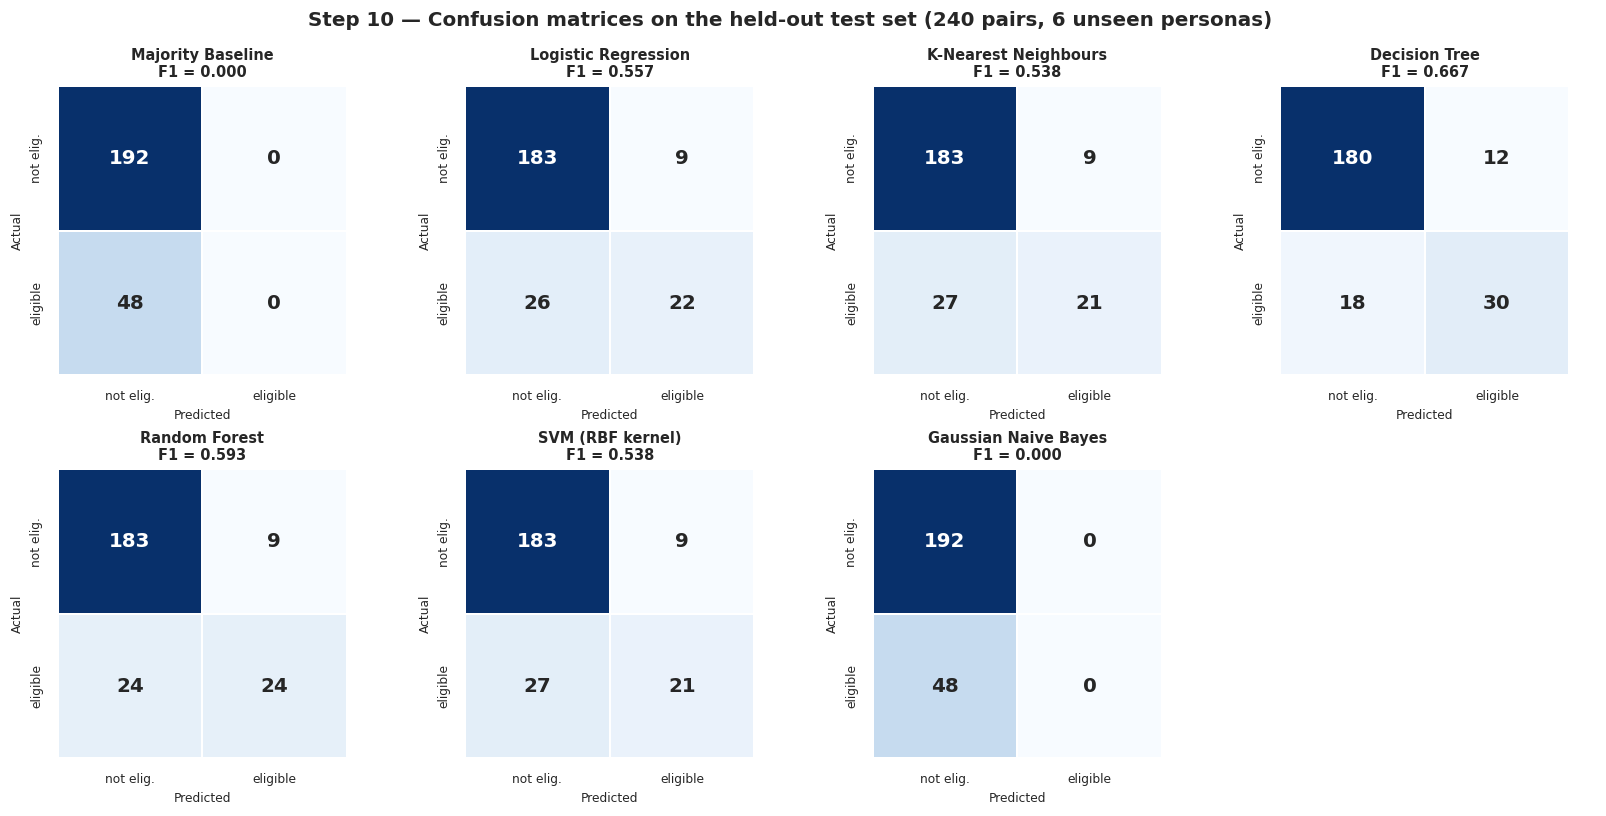

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                square=True, linewidths=1.2, linecolor="white",
                annot_kws={"size": 13, "weight": "bold"},
                xticklabels=["not elig.", "eligible"],
                yticklabels=["not elig.", "eligible"], ax=ax)
    ax.set_title(f"{name}\nF1 = {f1_score(y_test, y_pred, zero_division=0):.3f}",
                 fontsize=9.5, weight="bold")
    ax.set_xlabel("Predicted", fontsize=8)
    ax.set_ylabel("Actual", fontsize=8)
    ax.tick_params(labelsize=8)

for ax in axes.ravel()[len(preds):]:
    ax.axis("off")

fig.suptitle(f"Step 10 — Confusion matrices on the held-out test set "
             f"({len(y_test)} pairs, {g_test.nunique()} unseen personas)",
             fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig(FIGDIR / "06_confusion_matrices.png"); plt.show()

In [32]:
# The best model, cell by cell
scored = results.drop(index="Majority Baseline")
best_name = scored["F1"].idxmax()
cm = confusion_matrix(y_test, preds[best_name])

not_elig_correct = cm[0, 0]
false_alarm      = cm[0, 1]
missed           = cm[1, 0]
elig_correct     = cm[1, 1]

print(f"Best model by F1: {best_name}\n")
print(f"  {not_elig_correct:>4}  correctly ruled out")
print(f"  {false_alarm:>4}  recommended but not actually eligible   <- wasted application")
print(f"  {missed:>4}  eligible but NOT recommended            <- ENTITLEMENT MISSED")
print(f"  {elig_correct:>4}  correctly recommended")
print()
print(f"  Total: {cm.sum()} pairs | correct: {not_elig_correct + elig_correct} "
      f"| wrong: {false_alarm + missed}")

Best model by F1: Decision Tree

   180  correctly ruled out
    12  recommended but not actually eligible   <- wasted application
    18  eligible but NOT recommended            <- ENTITLEMENT MISSED
    30  correctly recommended

  Total: 240 pairs | correct: 210 | wrong: 30


---
## 11. Compare All Baseline Models

In [33]:
# 11.1 Ranked comparison
comparison_table = results.sort_values("F1", ascending=False).round(4)
comparison_table

,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1 (mean),CV F1 (std),Fit time (ms)
Model,,,,,,,,
Decision Tree,0.8750,0.7143,0.6250,0.6667,0.7812,0.8450,0.0559,4.4196
Random Forest,0.8625,0.7273,0.5000,0.5926,0.8326,0.7923,0.0770,425.8746
Logistic Regression,0.8542,0.7097,0.4583,0.5570,0.7815,0.6599,0.0745,10.5012
SVM (RBF kernel),0.8500,0.7000,0.4375,0.5385,0.8504,0.6968,0.0853,78.0702
K-Nearest Neighbours,0.8500,0.7000,0.4375,0.5385,0.8080,0.7229,0.0483,4.0514
Majority Baseline,0.8000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0000,0.6975
Gaussian Naive Bayes,0.8000,0.0000,0.0000,0.0000,0.5689,0.0000,0.0000,3.5400


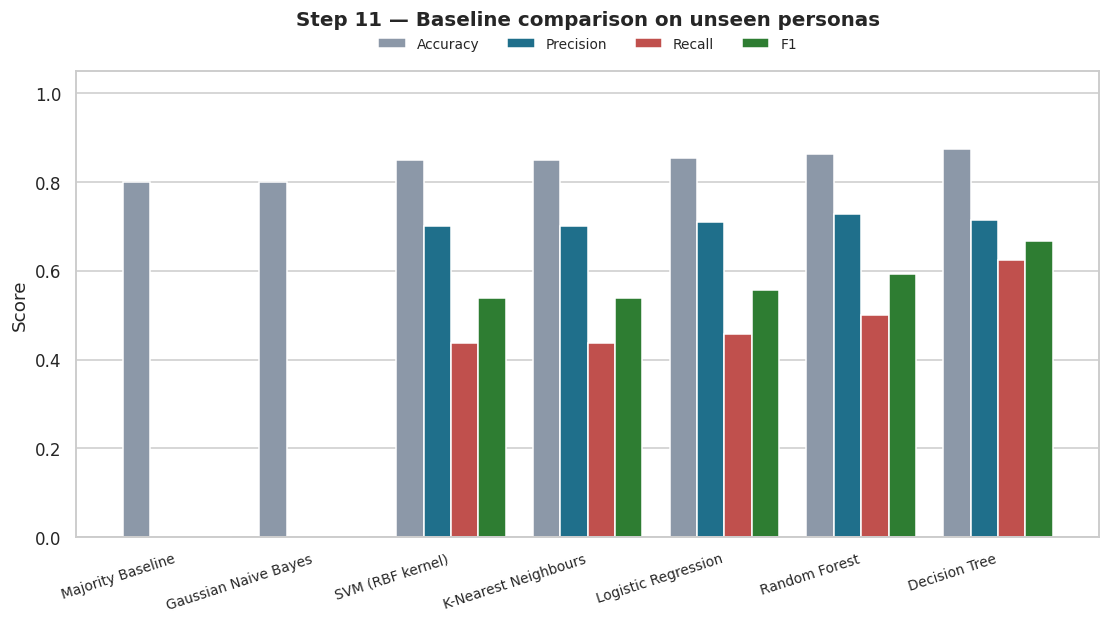

Note the Majority Baseline: high accuracy, ZERO recall. That single pair of bars
is the clearest possible argument against reporting accuracy on this dataset.


In [34]:
# 11.2 Grouped bar chart
metrics = ["Accuracy", "Precision", "Recall", "F1"]
plot_df = results[metrics].sort_values("F1")

fig, ax = plt.subplots(figsize=(12, 5.5))
xpos = np.arange(len(plot_df)); width = 0.2
colours = ["#8c98a8", "#1f6f8b", "#c0504d", "#2e7d32"]
for i, (metric, colour) in enumerate(zip(metrics, colours)):
    offset = (i - (len(metrics) - 1) / 2) * width
    ax.bar(xpos + offset, plot_df[metric], width, label=metric, color=colour)

ax.set_xticks(xpos)
ax.set_xticklabels(plot_df.index, rotation=18, ha="right", fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Step 11 — Baseline comparison on unseen personas",
             fontsize=13, weight="bold", pad=30)
ax.legend(fontsize=9, ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, 1.10), frameon=False)
ax.grid(axis="x", visible=False)
plt.savefig(FIGDIR / "07_model_comparison.png"); plt.show()

print("Note the Majority Baseline: high accuracy, ZERO recall. That single pair of bars")
print("is the clearest possible argument against reporting accuracy on this dataset.")

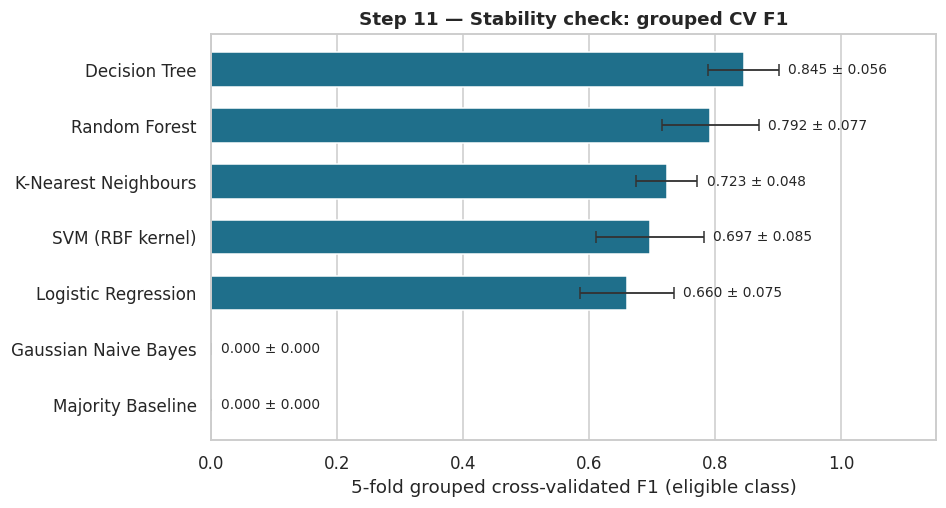

The error bars are WIDE. With only 14 training personas, each CV fold trains on
about 11 personas — so fold-to-fold variation is large and small differences in
the ranking above should not be trusted.


In [35]:
# 11.3 Cross-validated F1 with error bars
cv_df = results[["CV F1 (mean)", "CV F1 (std)"]].sort_values("CV F1 (mean)")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(cv_df.index, cv_df["CV F1 (mean)"], xerr=cv_df["CV F1 (std)"],
        color="#1f6f8b", error_kw={"ecolor": "#333", "capsize": 4, "lw": 1.2},
        height=0.62)
for i, (m, s) in enumerate(zip(cv_df["CV F1 (mean)"], cv_df["CV F1 (std)"])):
    ax.text(m + s + 0.015, i, f"{m:.3f} ± {s:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.15)
ax.set_xlabel("5-fold grouped cross-validated F1 (eligible class)")
ax.set_title("Step 11 — Stability check: grouped CV F1",
             fontsize=12, weight="bold")
ax.grid(axis="y", visible=False)
plt.savefig(FIGDIR / "08_cv_f1.png"); plt.show()

print("The error bars are WIDE. With only 14 training personas, each CV fold trains on")
print("about 11 personas — so fold-to-fold variation is large and small differences in")
print("the ranking above should not be trusted.")

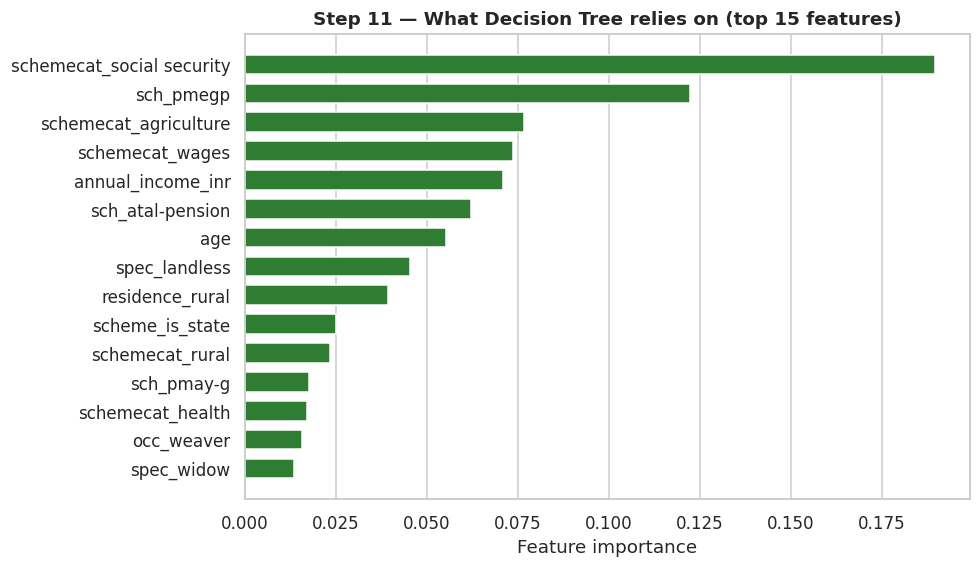

Total importance on SCHEME-side features : 0.682
Total importance on CITIZEN-side features: 0.318

THIS IS THE MOST REVEALING RESULT IN THE NOTEBOOK, and it is not the
flattering one. The corpus constrains annual_income_inr in 15 clauses,
age in 15, special_categories in 11, occupation in 10 and education_stage
in 10 — so a model that had genuinely learned the RULES would lean on those
citizen fields. Instead the top of the chart is dominated by scheme identity
and scheme category: 'which scheme is this' rather than 'who is this person'.

In other words the tree has largely learned each scheme's BASE RATE — how
often it is granted across the training personas — and uses the citizen's
income and age only as a secondary correction. That is memorisation of the
label distribution, not recovery of the eligibility logic, and it is exactly
what you would expect from 14 training personas.


In [36]:
# 11.4 What did the best model actually learn?
best_est = fitted[best_name].named_steps["model"]
if hasattr(best_est, "feature_importances_"):
    imp = (pd.Series(best_est.feature_importances_, index=feature_cols)
             .sort_values(ascending=False).head(15))

    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.barh(imp.index[::-1], imp.values[::-1], color="#2e7d32", height=0.68)
    ax.set_xlabel("Feature importance")
    ax.set_title(f"Step 11 — What {best_name} relies on (top 15 features)",
                 fontsize=12, weight="bold")
    ax.grid(axis="y", visible=False)
    plt.savefig(FIGDIR / "09_feature_importance.png"); plt.show()

    # Where does the model's attention actually go?
    all_imp = pd.Series(best_est.feature_importances_, index=feature_cols)
    scheme_side = all_imp[[c for c in feature_cols
                           if c.startswith(("sch_", "scheme", "schemecat_"))]].sum()
    citizen_side = all_imp.sum() - scheme_side

    print(f"Total importance on SCHEME-side features : {scheme_side:.3f}")
    print(f"Total importance on CITIZEN-side features: {citizen_side:.3f}")
    print()
    print("THIS IS THE MOST REVEALING RESULT IN THE NOTEBOOK, and it is not the")
    print("flattering one. The corpus constrains annual_income_inr in 15 clauses,")
    print("age in 15, special_categories in 11, occupation in 10 and education_stage")
    print("in 10 — so a model that had genuinely learned the RULES would lean on those")
    print("citizen fields. Instead the top of the chart is dominated by scheme identity")
    print("and scheme category: 'which scheme is this' rather than 'who is this person'.")
    print()
    print("In other words the tree has largely learned each scheme's BASE RATE — how")
    print("often it is granted across the training personas — and uses the citizen's")
    print("income and age only as a secondary correction. That is memorisation of the")
    print("label distribution, not recovery of the eligibility logic, and it is exactly")
    print("what you would expect from 14 training personas.")
else:
    print(f"{best_name} exposes no feature_importances_.")

In [37]:
# 11.5 Verdict
scored = results.drop(index="Majority Baseline")
best_f1     = scored["F1"].idxmax()
best_recall = scored["Recall"].idxmax()
most_stable = scored["CV F1 (std)"].idxmin()
maj_acc     = results.loc["Majority Baseline", "Accuracy"]

print("SUMMARY")
print("=" * 66)
print(f"Best F1 (eligible class)   : {best_f1}  "
      f"({scored.loc[best_f1, 'F1']:.4f})")
print(f"Best recall (fewest missed): {best_recall}  "
      f"({scored.loc[best_recall, 'Recall']:.4f})")
print(f"Most stable across folds   : {most_stable}  "
      f"(CV F1 std {scored.loc[most_stable, 'CV F1 (std)']:.4f})")
print(f"Majority-class accuracy    : {maj_acc:.4f}  (recall 0.0000)")
print("=" * 66)
print()
print("WHAT THIS MEANS FOR YOJANAMITRA")
print()
print("1. Tree-based models lead, and the gap is clearest in cross-validation rather")
print("   than on the single test split. Eligibility is a CONJUNCTION of threshold")
print("   tests, which is exactly the shape a decision tree represents natively and a")
print("   linear boundary cannot.")
print()
print("2. Gaussian Naive Bayes collapses to predicting 'not eligible' for everything.")
print("   Its independence assumption is fatal here: eligibility depends on features")
print("   INTERACTING, which is precisely what that assumption forbids.")
print()
print("3. The rule engine is not beaten here — it DEFINED the labels, so it scores 1.0")
print("   by construction. The honest reading is the reverse: the gap between the best")
print("   model and 1.0 measures how much of the rule set is NOT recoverable from 14")
print("   training personas — and the feature importances above show that what WAS")
print("   learned is largely per-scheme base rates, not the clause logic itself.")
print()
print("4. Even at equal accuracy, the learned model would be the wrong choice for this")
print("   project. YojanaMitra has to tell a citizen WHICH clause they failed and why.")
print("   The rule engine emits that for free; a Random Forest emits a probability.")
print("   Feature importances are not a per-citizen legal explanation.")
print()
print("5. The real bottleneck is data, not algorithms. 20 personas over 40 schemes is a")
print("   demonstration, not a training set. Any serious attempt needs hundreds of")
print("   verified profiles, and the corpus itself needs verifying against the live")
print("   portal before any accuracy claim leaves this notebook.")

SUMMARY
Best F1 (eligible class)   : Decision Tree  (0.6667)
Best recall (fewest missed): Decision Tree  (0.6250)
Most stable across folds   : Gaussian Naive Bayes  (CV F1 std 0.0000)
Majority-class accuracy    : 0.8000  (recall 0.0000)

WHAT THIS MEANS FOR YOJANAMITRA

1. Tree-based models lead, and the gap is clearest in cross-validation rather
   than on the single test split. Eligibility is a CONJUNCTION of threshold
   tests, which is exactly the shape a decision tree represents natively and a
   linear boundary cannot.

2. Gaussian Naive Bayes collapses to predicting 'not eligible' for everything.
   Its independence assumption is fatal here: eligibility depends on features
   INTERACTING, which is precisely what that assumption forbids.

3. The rule engine is not beaten here — it DEFINED the labels, so it scores 1.0
   by construction. The honest reading is the reverse: the gap between the best
   model and 1.0 measures how much of the rule set is NOT recoverable from 14
   trai

In [38]:
# Persist results so the report cannot disagree with the notebook
results.to_csv("model_results.csv")
summary = {
    "n_utterances": len(gold),
    "n_personas": int(df_clean["persona"].nunique()),
    "n_schemes": len(schemes),
    "n_rows_raw": int(len(df)),
    "n_rows_clean": int(len(df_model)),
    "n_features": len(feature_cols),
    "positive_rate": float(df_model["eligible"].mean()),
    "n_train_rows": int(len(X_train)),
    "n_test_rows": int(len(X_test)),
    "n_train_personas": int(g_train.nunique()),
    "n_test_personas": int(g_test.nunique()),
    "test_personas": sorted(set(g_test)),
    "leaky_f1": float(bad_f1),
    "grouped_f1": float(good_f1),
    "leaky_acc": float(bad_acc),
    "grouped_acc": float(good_acc),
    "best_model": best_f1,
    "majority_accuracy": float(maj_acc),
    "n_test_eligible": int((y_test == 1).sum()),
    "n_schemes_never_matched": int((df.groupby("scheme_id")["eligible"]
                                      .mean() == 0).sum()),
    "importance_scheme_side": float(scheme_side),
    "importance_citizen_side": float(citizen_side),
}
Path("run_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved -> model_results.csv, run_summary.json, figures/")
print(json.dumps(summary, indent=2)[:900])

Saved -> model_results.csv, run_summary.json, figures/
{
  "n_utterances": 60,
  "n_personas": 20,
  "n_schemes": 40,
  "n_rows_raw": 2400,
  "n_rows_clean": 800,
  "n_features": 106,
  "positive_rate": 0.19125,
  "n_train_rows": 560,
  "n_test_rows": 240,
  "n_train_personas": 14,
  "n_test_personas": 6,
  "test_personas": [
    "ap-small-farmer-daughter",
    "disabled-adult-bpl",
    "sc-engineering-student",
    "st-class9-student",
    "urban-street-vendor",
    "young-entrepreneur-sc"
  ],
  "leaky_f1": 0.8372093023255814,
  "grouped_f1": 0.5925925925925926,
  "leaky_acc": 0.9416666666666667,
  "grouped_acc": 0.8625,
  "best_model": "Decision Tree",
  "majority_accuracy": 0.8,
  "n_test_eligible": 48,
  "n_schemes_never_matched": 4,
  "importance_scheme_side": 0.6816549463974095,
  "importance_citizen_side": 0.31834505360259036
}
